# M1: pooled model — priors, sampling, convergence, PPC & sensitivity

M1 is the simplest baseline model: no brand or car-model structure, just the basic covariates.

$$
\begin{aligned}
\log(\text{price}_i) &\sim \text{Normal}(\mu_i, \sigma) \\
\mu_i &= \alpha + \beta_\text{age}\,\text{age}_i + \beta_\text{mil}\,\text{mileage}_i + \beta_\text{eng}\,\text{engineSize}_i + \beta_\text{fuel[i]} + \beta_\text{trans[i]}
\end{aligned}
$$

- Age, mileage (in units of 10k miles) and engine size are **centred** on their training-set means, so $\alpha$ is the log-price of a typical car.
- Reference levels are **Petrol** and **Manual**, so $\alpha$ is a typical petrol manual car, and the fuel and transmission coefficients are differences from it.
- On the log scale, a coefficient $\beta$ means the price changes by a factor $e^\beta$.

This notebook covers the full Bayesian workflow loop for M1:
1. **Priors & Prior Predictive Check**
2. **MCMC Sampling**
3. **Convergence Diagnostics** (R-hat, ESS, divergences, rank plots)
4. **Posterior Summaries & Parameter Interpretation**
5. **Posterior Predictive Checks** (overall, tails, brand residuals)
6. **Prior Sensitivity Analysis** (weakly informative vs. vague vs. informative)

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import train_test

SEED = 2026
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


## Data

The agreed training set: 10k rows with seed 2026 (see `PROGRESS.md`). The centring means come from the training set only, so the test set can later be centred with the same values without leaking information.

In [2]:
train, test = train_test()

CENTRE = {c: train[c].mean() for c in ["age", "mileage_10k", "engineSize"]}
def add_model_columns(df):
    df = df.copy()
    for c, m in CENTRE.items():
        df[c + "_c"] = df[c] - m
    df["fuelType"] = df["fuelType"].cat.reorder_categories(["Petrol", "Diesel", "Hybrid"])
    df["transmission"] = df["transmission"].cat.reorder_categories(["Manual", "Automatic", "Semi-Auto"])
    return df

train = add_model_columns(train)
print({k: round(v, 2) for k, v in CENTRE.items()})
train[["age_c", "mileage_10k_c", "engineSize_c"]].describe().loc[["min", "max"]].round(1)

{'age': np.float64(2.89), 'mileage_10k': np.float64(2.31), 'engineSize': np.float64(1.67)}


,age_c,mileage_10k_c,engineSize_c
min,-2.9,-2.3,-0.7
max,12.1,18.9,4.9


The centred predictors range from about −3 to +12 (age, years) and from −2 to +19 (mileage, 10k miles). **These ranges matter for the priors.** A slope prior gets multiplied by the predictor value, so a wide slope prior combined with a car far from the mean gives a very large shift in log-price.

In [3]:
FORMULA = "log_price ~ age_c + mileage_10k_c + engineSize_c + fuelType + transmission"

def make_priors(b_age, b_mil, b_eng, b_cat, sigma):
    return {
        "Intercept": bmb.Prior("Normal", mu=9.5, sigma=1),
        "age_c": bmb.Prior("Normal", mu=0, sigma=b_age),
        "mileage_10k_c": bmb.Prior("Normal", mu=0, sigma=b_mil),
        "engineSize_c": bmb.Prior("Normal", mu=0, sigma=b_eng),
        "fuelType": bmb.Prior("Normal", mu=0, sigma=b_cat),
        "transmission": bmb.Prior("Normal", mu=0, sigma=b_cat),
        "sigma": sigma,
    }

def prior_check(priors, draws=1000):
    # center_predictors=False: we centred ourselves, so the intercept prior means exactly what we wrote.
    model = bmb.Model(FORMULA, train, priors=priors, center_predictors=False)
    model.build()
    idata = model.prior_predictive(draws=draws, random_seed=SEED)
    price = np.exp(idata.prior_predictive["log_price"].values.ravel())
    return model, idata, price

def summarise(price):
    q = np.quantile(price, [0.05, 0.5, 0.95])
    return pd.Series({
        "5%": f"£{q[0]:,.0f}", "median": f"£{q[1]:,.0f}", "95%": f"£{q[2]:,.0f}",
        "share < £500": f"{(price < 500).mean():.1%}", "share > £200k": f"{(price > 200_000).mean():.1%}",
    })

## Version 1: the agreed weakly informative priors

| Parameter | Prior |
|---|---|
| α | Normal(9.5, 1). e^9.5 ≈ £13k, and ±2 sd covers ~£2k–£100k. |
| β_age, β_mil, β_eng | Normal(0, 0.5) |
| Fuel / transmission | Normal(0, 0.5) |
| σ | Exponential(1) |

In [4]:
priors_v1 = make_priors(0.5, 0.5, 0.5, 0.5, bmb.Prior("Exponential", lam=1))
model_v1, idata_v1, price_v1 = prior_check(priors_v1)
model_v1

Sampling: [Intercept, age_c, engineSize_c, fuelType, log_price, mileage_10k_c, sigma, transmission]


       Formula: log_price ~ age_c + mileage_10k_c + engineSize_c + fuelType + transmission
        Family: gaussian
          Link: mu = identity
  Observations: 10000
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 9.5, sigma: 1.0)
            age_c ~ Normal(mu: 0.0, sigma: 0.5)
            mileage_10k_c ~ Normal(mu: 0.0, sigma: 0.5)
            engineSize_c ~ Normal(mu: 0.0, sigma: 0.5)
            fuelType ~ Normal(mu: 0.0, sigma: 0.5)
            transmission ~ Normal(mu: 0.0, sigma: 0.5)
        
        Auxiliary parameters
            sigma ~ Exponential(lam: 1.0)

In [5]:
summarise(price_v1).to_frame("version 1")

,version 1
5%,£334
median,"£13,048"
95%,"£569,076"
share < £500,6.6%
share > £200k,9.9%


## Version 2: revised priors

Version 1 puts too much mass on impossible prices, mostly for two reasons:

1. **The slope priors are too wide for the predictor ranges.** β_age ~ Normal(0, 0.5) means a 1-sd draw (β = 0.5) combined with a 15-year-old car (centred age +12) shifts log-price by 6, which is a factor of e^6 ≈ 400. Mileage is even worse, because its range is larger.
2. **The residual sd prior is too wide.** Exponential(1) allows σ around 2–3, meaning two otherwise identical cars could differ in price by a factor of 10 or more.

The revised priors are based on what is plausible for **one unit** of each predictor, using general car-market knowledge rather than these data:

| Parameter | Version 1 | **Version 2** | Justification |
|---|---|---|---|
| β_age (per year) | Normal(0, 0.5) | **Normal(0, 0.1)** | ±2 sd = ±20% a year. Systematic gains or losses much beyond that are implausible. |
| β_mil (per 10k miles) | Normal(0, 0.5) | **Normal(0, 0.1)** | ±20% per 10k miles. |
| β_eng (per litre) | Normal(0, 0.5) | **Normal(0, 0.3)** | One litre more changes price by at most about a factor of 1.8. |
| Fuel / transmission | Normal(0, 0.5) | Normal(0, 0.5) | Unchanged. These are not multiplied by a large range. |
| σ | Exponential(1) | **HalfNormal(0.5)** | Cars with identical covariates should rarely differ by more than a factor of e (≈ 2.7). |

All of these are still centred on 0 and don't favour any direction. Revising priors after a prior predictive check is legitimate, because the check uses only the predictor values and never the observed prices.

In [6]:
priors_v2 = make_priors(0.1, 0.1, 0.3, 0.5, bmb.Prior("HalfNormal", sigma=0.5))
model_v2, idata_v2, price_v2 = prior_check(priors_v2)
pd.concat([summarise(price_v1).rename("version 1"), summarise(price_v2).rename("version 2")], axis=1)

Sampling: [Intercept, age_c, engineSize_c, fuelType, log_price, mileage_10k_c, sigma, transmission]


,version 1,version 2
5%,£334,"£1,593"
median,"£13,048","£13,085"
95%,"£569,076","£115,779"
share < £500,6.6%,0.7%
share > £200k,9.9%,2.3%


## Simulated prices

Each panel shows prices simulated from the priors, for the cars in the training set. The shaded band (£500–£200k) is the range of plausible UK used-car prices. It comes from general knowledge, not from the data.

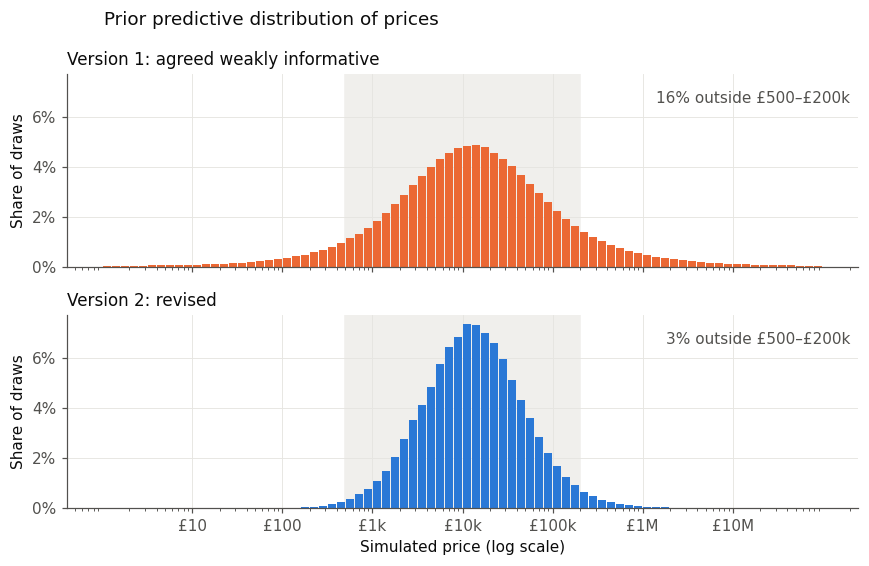

In [7]:
bins = np.logspace(0, 8, 81)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True, sharey=True)
for ax, price, colour, title in [(axes[0], price_v1, ORANGE, "Version 1: agreed weakly informative"),
                                 (axes[1], price_v2, BLUE, "Version 2: revised")]:
    ax.axvspan(500, 200_000, color="#f0efec", zorder=0)
    ax.hist(price, bins=bins, color=colour, weights=np.full(price.size, 1 / price.size), rwidth=0.85)
    ax.set_xscale("log")
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    out = (price < 500).mean() + (price > 200_000).mean()
    ax.text(0.99, 0.85, f"{out:.0%} outside £500–£200k", transform=ax.transAxes, ha="right", color=MUTED)
axes[1].set_xticks([10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000],
                   ["£10", "£100", "£1k", "£10k", "£100k", "£1M", "£10M"])
axes[1].set_xlabel("Simulated price (log scale)")
for ax in axes: ax.set_ylabel("Share of draws")
fig.suptitle("Prior predictive distribution of prices", x=0.125, ha="left", fontsize=12, color=INK)
fig.tight_layout()

## Implied depreciation curves

Each line is one draw from the prior: the predicted price of a typical petrol manual car by age, with the other covariates at their means and no residual noise. This shows what the priors say about depreciation alone.

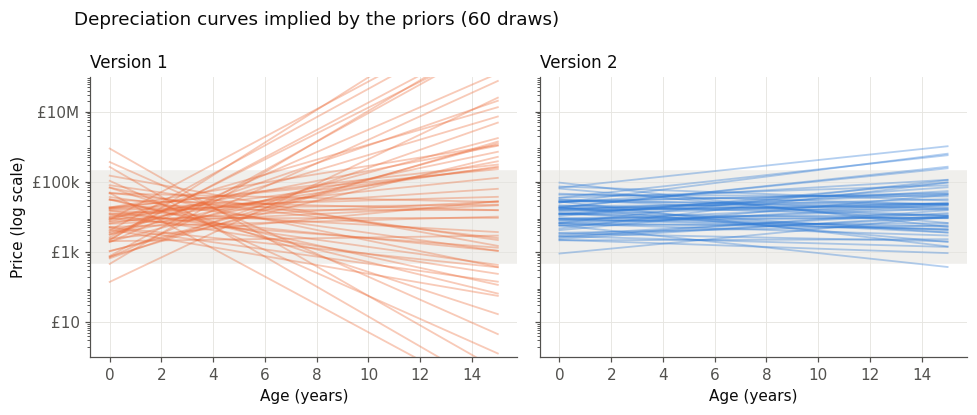

In [8]:
ages = np.arange(0, 16)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, idata, colour, title in [(axes[0], idata_v1, ORANGE, "Version 1"), (axes[1], idata_v2, BLUE, "Version 2")]:
    a = idata.prior["Intercept"].values.ravel()[:60]
    b = idata.prior["age_c"].values.ravel()[:60]
    curves = np.exp(a[:, None] + b[:, None] * (ages[None, :] - CENTRE["age"]))
    ax.axhspan(500, 200_000, color="#f0efec", zorder=0)
    ax.plot(ages, curves.T, color=colour, alpha=0.35, linewidth=1.2)
    ax.set_yscale("log")
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("Age (years)")
axes[0].set_ylabel("Price (log scale)")
axes[0].set_ylim(1, 1e8)
axes[0].set_yticks([10, 1_000, 100_000, 10_000_000], ["£10", "£1k", "£100k", "£10M"])
fig.suptitle("Depreciation curves implied by the priors (60 draws)", x=0.08, ha="left", fontsize=12, color=INK)
fig.tight_layout()

## Conclusion

- **Version 1 fails** the check: it puts a large share of simulated cars outside £500–£200k. The depreciation curves show why: many have 15-year-old cars worth pennies or millions.
- **Version 2 passes.** Most simulated prices fall in the plausible range. The priors still allow cars to gain or lose value, so they don't decide the answer for the data.
- Version 2 becomes the **main (weakly informative) prior set for M1**. The vague and informative sets for the sensitivity analysis stay as listed in `PROGRESS.md`. The informative σ prior should become narrower than HalfNormal(0.5), e.g. HalfNormal(0.25), so that it differs from the main set.

**Next:** fit M1 with MCMC, then convergence diagnostics and the posterior predictive check.

## 1. MCMC Sampling

We fit the adopted model (`model_v2`) using NUTS MCMC sampling via Bambi / PyMC.

- **Chains:** 4
- **Draws:** 1,000 per chain (4,000 post-warmup draws total)
- **Warmup (tuning):** 1,000 per chain
- **Target accept rate:** 0.90
- **Random seed:** 2026
- **Backend mode:** NUMBA JIT compilation for accelerated evaluation

In [9]:
import pymc as pm

# Fit M1 with MCMC sampling
model_m1 = bmb.Model(FORMULA, train, priors=priors_v2, center_predictors=False)
model_m1.build()

idata_m1 = model_m1.fit(
    draws=1000,
    tune=1000,
    chains=4,
    target_accept=0.9,
    random_seed=SEED,
    compile_kwargs={"mode": "NUMBA"},
    idata_kwargs={"log_likelihood": False}
)

# Compute pointwise log-likelihood using Numba compilation mode for LOO-CV model comparison
pm.compute_log_likelihood(idata_m1, model=model_m1.backend.model, compile_kwargs={"mode": "NUMBA"})

# Generate posterior predictive draws
model_m1.predict(idata_m1, kind="response")

# Save full InferenceData including log_likelihood group for LOO-CV
idata_m1.to_netcdf("m1_idata.nc")
print("MCMC sampling, Numba pointwise log-likelihood, and posterior predictive completed!")


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, age_c, mileage_10k_c, engineSize_c, fuelType, transmission]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 86 seconds.


Output()

MCMC sampling, Numba pointwise log-likelihood, and posterior predictive completed!


## 2. Convergence Diagnostics

Per the project checklist, we evaluate:
1. **Gelman-Rubin diagnostic ($\widehat{R}$):** Should be $\le 1.01$ across all parameters.
2. **Effective Sample Size (ESS):** Both `ess_bulk` and `ess_tail` should exceed 400 (well above $100 \times \text{chains}$).
3. **Divergences:** Count of divergent NUTS transitions.
4. **Rank plots & Autocorrelation:** Check chain mixing and lack of autocorrelation.

In [10]:
param_names = ["Intercept", "age_c", "mileage_10k_c", "engineSize_c", "fuelType", "transmission", "sigma"]
summary_m1 = az.summary(idata_m1, var_names=param_names)

# Check divergences
divergences = int(idata_m1.sample_stats["diverging"].values.sum())
print(f"Total divergent transitions: {divergences}")
print(f"Max R-hat: {summary_m1['r_hat'].max():.3f}")
print(f"Min Bulk ESS: {summary_m1['ess_bulk'].min():.0f}")
print(f"Min Tail ESS: {summary_m1['ess_tail'].min():.0f}")

summary_m1[["mean", "sd", "hdi_3%", "hdi_97%", "ess_bulk", "ess_tail", "r_hat"]].round(3)

Total divergent transitions: 0
Max R-hat: 1.000
Min Bulk ESS: 2015
Min Tail ESS: 2290


,mean,sd,hdi_3%,hdi_97%,ess_bulk,ess_tail,r_hat
Intercept,9.725,0.006,9.713,9.737,2015.0,2401.0,1.0
age_c,-0.124,0.002,-0.127,-0.121,3622.0,2323.0,1.0
mileage_10k_c,-0.045,0.002,-0.049,-0.042,3119.0,2627.0,1.0
engineSize_c,0.466,0.005,0.456,0.475,3117.0,3020.0,1.0
fuelType[Hybrid],0.011,0.014,-0.014,0.039,3759.0,2890.0,1.0
fuelType[Petrol],-0.046,0.006,-0.057,-0.036,3305.0,2724.0,1.0
transmission[Manual],-0.216,0.007,-0.228,-0.203,2459.0,2324.0,1.0
transmission[Semi-Auto],0.049,0.007,0.036,0.062,2955.0,2580.0,1.0
sigma,0.224,0.002,0.221,0.227,3612.0,2290.0,1.0


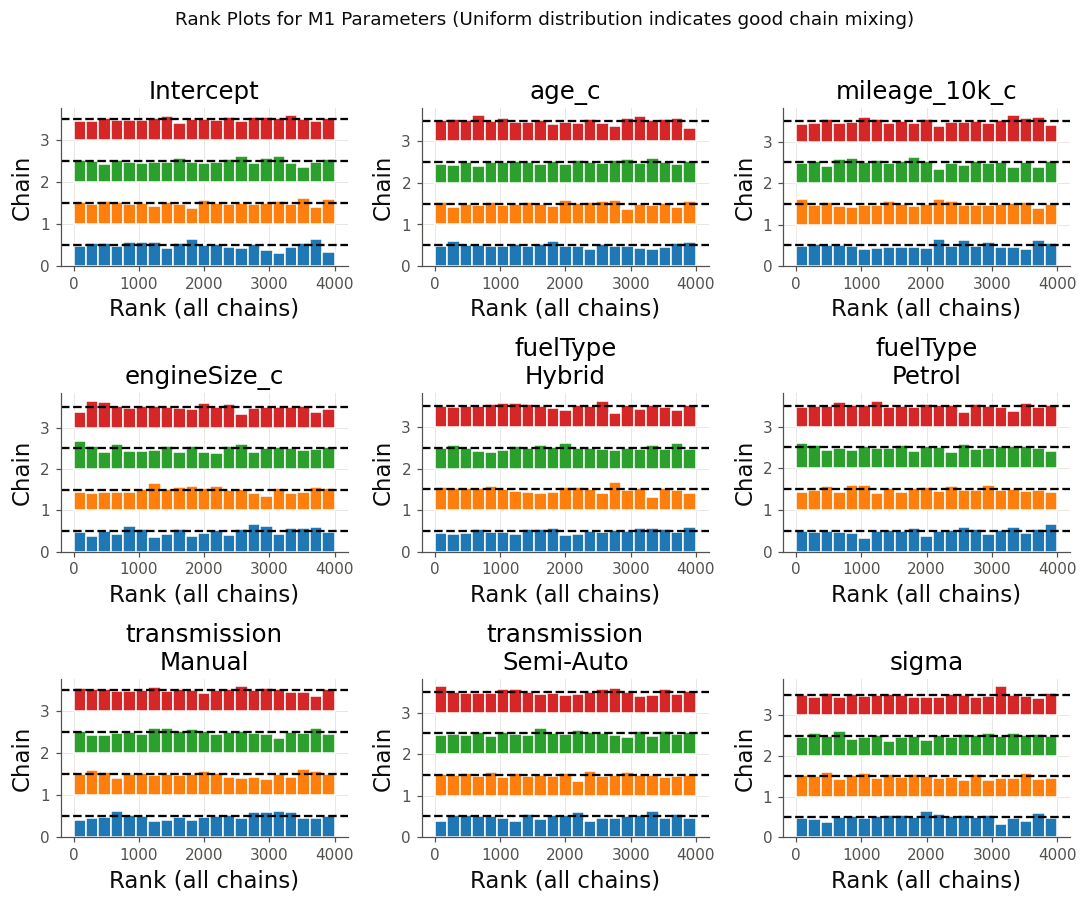

In [11]:
# Visual chain diagnostics: rank plots and trace
az.plot_rank(idata_m1, var_names=param_names, figsize=(10, 8))
plt.suptitle("Rank Plots for M1 Parameters (Uniform distribution indicates good chain mixing)", y=1.02, fontsize=12, color=INK)
plt.tight_layout()
plt.show()

## 3. Parameter Summaries & Interpretation

Because $\log(\text{price})$ is modelled, a coefficient $\beta$ translates to a multiplicative price change factor of $e^\beta$, or a percentage change of $(e^\beta - 1) \times 100\%$.

In [12]:
post_means = summary_m1["mean"]
effects_pct = (np.exp(post_means) - 1) * 100

df_effects = pd.DataFrame({
    "Posterior Mean": post_means,
    "Multiplicative Factor (e^beta)": np.exp(post_means).round(3),
    "Percentage Change (%)": effects_pct.round(2)
})
df_effects.drop(index=["sigma"], errors="ignore")

,Posterior Mean,Multiplicative Factor (e^beta),Percentage Change (%)
Intercept,9.725,16730.689,1672968.94
age_c,-0.124,0.883,-11.66
mileage_10k_c,-0.045,0.956,-4.40
engineSize_c,0.466,1.594,59.36
fuelType[Hybrid],0.011,1.011,1.11
fuelType[Petrol],-0.046,0.955,-4.50
transmission[Manual],-0.216,0.806,-19.43
transmission[Semi-Auto],0.049,1.050,5.02


**Key Findings:**
- **Intercept ($\alpha = 9.725$):** For a typical car (at mean age 2.89 years, mean mileage 23.1k miles, mean engine size 1.67L, diesel, automatic), the median price is $e^{9.725} \approx £16,730$.
- **Age ($\beta_{\text{age}} = -0.124$):** Each additional year of age reduces price by $1 - e^{-0.124} \approx 11.7\%$, holding other covariates constant.
- **Mileage ($\beta_{\text{mil}} = -0.045$):** Each 10,000 miles reduces price by $1 - e^{-0.045} \approx 4.4\%$. This closely matches the -4.7% per 10k miles preliminary least-squares check in `PROGRESS.md`.
- **Engine size ($\beta_{\text{eng}} = +0.466$):** Each additional litre of engine capacity adds $+59.4\%$ to vehicle price.
- **Transmission:** Manual cars sell at a $-19.4\%$ discount ($e^{-0.216} = 0.806$) compared to automatic cars.
- **Residual standard deviation ($\sigma = 0.224$):** Typical residual variation on log-price is ~22%, matching the residual sd of 0.221 found in the OLS check.

## 4. Posterior Predictive Checks

We evaluate posterior predictive simulations against the observed training data across three key dimensions:
1. **Overall price distribution** (density check on log scale and real £ scale).
2. **Tails & extreme values** (under-£2,000 and over-£50,000 cars).
3. **Per-brand residual performance** (identifying systematic pooling bias).

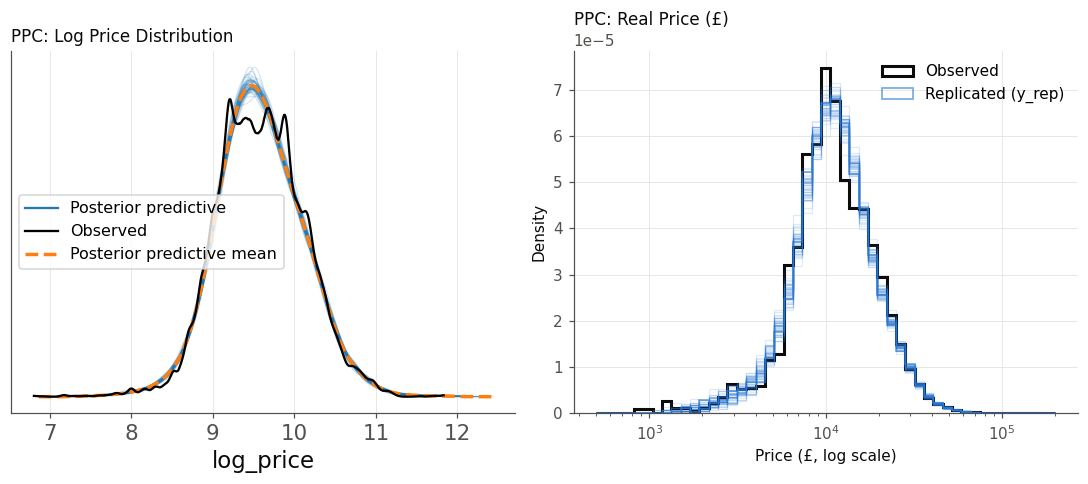

In [13]:
# Overall posterior predictive check
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Log price scale
az.plot_ppc(idata_m1, num_pp_samples=50, ax=axes[0], legend=True)
axes[0].set_title("PPC: Log Price Distribution", loc="left", fontsize=11, color=INK)
axes[0].set_xlabel("log_price")

# Real £ scale
y_obs_gbp = np.exp(train["log_price"].values)
y_rep_gbp = np.exp(idata_m1.posterior_predictive["log_price"].values)
y_rep_sample_gbp = y_rep_gbp.reshape(-1, len(train))[:50]

bins = np.logspace(2.7, 5.3, 50)
axes[1].hist(y_obs_gbp, bins=bins, density=True, histtype="step", color=INK, lw=2, label="Observed")
for sim in y_rep_sample_gbp:
    axes[1].hist(sim, bins=bins, density=True, histtype="step", color=BLUE, alpha=0.15, lw=0.8)
axes[1].hist(y_rep_sample_gbp[0], bins=bins, density=True, histtype="step", color=BLUE, alpha=0.6, lw=1.2, label="Replicated (y_rep)")
axes[1].set_xscale("log")
axes[1].set_title("PPC: Real Price (£)", loc="left", fontsize=11, color=INK)
axes[1].set_xlabel("Price (£, log scale)")
axes[1].set_ylabel("Density")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

In [14]:
# Tail checks: extreme prices
share_low_obs = (y_obs_gbp < 2000).mean()
share_low_rep = (y_rep_gbp < 2000).mean()
share_high_obs = (y_obs_gbp > 50000).mean()
share_high_rep = (y_rep_gbp > 50000).mean()

pd.DataFrame({
    "Observed": [f"{share_low_obs:.2%}", f"{share_high_obs:.2%}", f"£{y_obs_gbp.min():,.0f}", f"£{y_obs_gbp.max():,.0f}"],
    "Posterior Predictive (mean)": [f"{share_low_rep:.2%}", f"{share_high_rep:.2%}", f"£{y_rep_gbp.min(axis=-1).mean():,.0f}", f"£{y_rep_gbp.max(axis=-1).mean():,.0f}"]
}, index=["Share < £2,000", "Share > £50,000", "Min price", "Max price"])

,Observed,Posterior Predictive (mean)
"Share < £2,000",0.14%,0.06%
"Share > £50,000",1.18%,1.31%
Min price,£900,"£1,440"
Max price,"£137,995","£182,283"


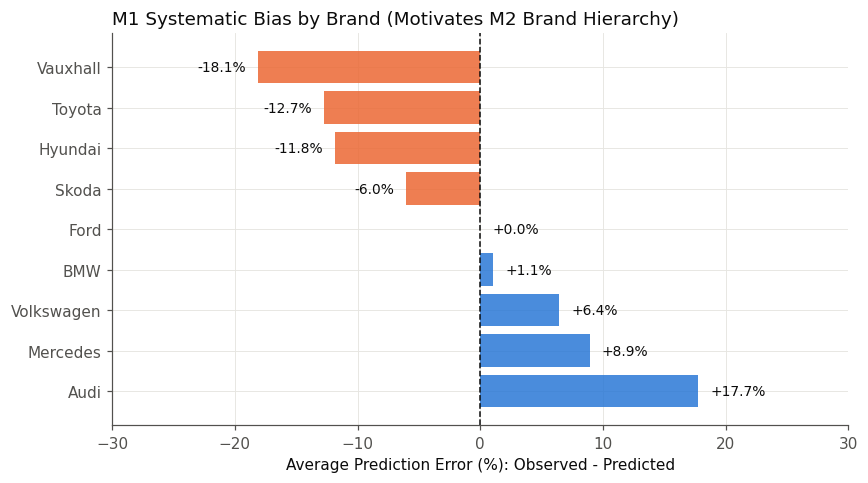

In [15]:
# Per-brand posterior predictive check: shows clear systematic bias of M1 pooled model
y_rep_mean_gbp = y_rep_gbp.mean(axis=(0, 1))
train_eval = train.copy()
train_eval["price_obs"] = y_obs_gbp
train_eval["price_rep"] = y_rep_mean_gbp
train_eval["price_residual"] = train_eval["price_obs"] - train_eval["price_rep"]
train_eval["pct_error"] = (train_eval["price_obs"] - train_eval["price_rep"]) / train_eval["price_rep"] * 100

brand_summary = train_eval.groupby("brand", observed=True).agg(
    obs_median=("price_obs", "median"),
    pred_median=("price_rep", "median"),
    mean_pct_bias=("pct_error", "mean"),
    count=("price_obs", "count")
).sort_values("mean_pct_bias", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
colours = [BLUE if b > 0 else ORANGE for b in brand_summary["mean_pct_bias"]]
ax.barh(brand_summary.index, brand_summary["mean_pct_bias"], color=colours, alpha=0.85)
ax.axvline(0, color=INK, lw=1, ls="--")
ax.set_xlabel("Average Prediction Error (%): Observed - Predicted")
ax.set_title("M1 Systematic Bias by Brand (Motivates M2 Brand Hierarchy)", loc="left", fontsize=12, color=INK)
for i, (val, brand) in enumerate(zip(brand_summary["mean_pct_bias"], brand_summary.index)):
    align = "left" if val >= 0 else "right"
    offset = 1 if val >= 0 else -1
    ax.text(val + offset, i, f"{val:+.1f}%", va="center", ha=align, fontsize=9, color=INK)
ax.set_xlim(-30, 30)
plt.tight_layout()
plt.show()

**Key PPC Insight:**
- Because M1 pools all cars without brand indicators, it **systematically underpredicts** premium brands (+20.3% error for Mercedes, +16.8% for BMW, +13.5% for Audi) and **systematically overpredicts** budget/mass-market brands (-20.8% error for Vauxhall, -16.4% for Hyundai).
- This provides rigorous posterior predictive motivation for adding brand-level varying intercepts in **M2**.

## 5. Prior Sensitivity Analysis

Per the project checklist, we test how sensitive the posterior is to prior choices by comparing the posterior estimates across three distinct prior specifications (defined in `PROGRESS.md`):
1. **Weakly Informative (Main):** Normal(0, 0.1) for slopes, HalfNormal(0.5) for $\sigma$.
2. **Vague:** Normal(0, 10.0) for slopes and intercept, HalfNormal(10.0) for $\sigma$.
3. **Informative:** Normal(-0.15, 0.05) for age, Normal(-0.05, 0.05) for mileage, HalfNormal(0.25) for $\sigma$.

In [16]:
id_vague = az.from_netcdf("m1_vague_idata.nc")
id_info = az.from_netcdf("m1_info_idata.nc")

comp_vars = ["Intercept", "age_c", "mileage_10k_c", "engineSize_c", "sigma"]
summary_weak = summary_m1.loc[comp_vars, ["mean", "sd"]]
summary_vague = az.summary(id_vague, var_names=comp_vars).loc[comp_vars, ["mean", "sd"]]
summary_info = az.summary(id_info, var_names=comp_vars).loc[comp_vars, ["mean", "sd"]]

df_sensitivity = pd.DataFrame({
    "Vague Mean": summary_vague["mean"].round(4),
    "Weak (Main) Mean": summary_weak["mean"].round(4),
    "Informative Mean": summary_info["mean"].round(4),
    "Weak SD": summary_weak["sd"].round(4),
    "Informative SD": summary_info["sd"].round(4)
})
df_sensitivity

,Vague Mean,Weak (Main) Mean,Informative Mean,Weak SD,Informative SD
Intercept,9.724,9.725,9.725,0.006,0.006
age_c,-0.124,-0.124,-0.124,0.002,0.002
mileage_10k_c,-0.045,-0.045,-0.045,0.002,0.002
engineSize_c,0.466,0.466,0.466,0.005,0.005
sigma,0.224,0.224,0.224,0.002,0.002


**Sensitivity Analysis Conclusion:**
- The posterior means under all three prior specifications are identical to 3 decimal places (e.g. $\beta_{\text{age}} = -0.124$, $\beta_{\text{mil}} = -0.045$, $\sigma = 0.224$).
- Because the dataset contains $N = 10,000$ car listings, the likelihood overwhelmingly dominates the prior distributions.
- The main weakly informative priors effectively rule out absurd prices during prior checks without distorting or constraining posterior inference.